# Hafta 9
# Sıfırdan GPT Tokenizer ve Byte Pair Encoding (BPE)

Son 8 haftada modelimiz metni harf harf okudu. Modern LLM'ler ise sık geçen harf/byte gruplarını tek bir **token** yapıyor. Bu notebook'ta bu mantığı sıfırdan kuruyoruz.

**İçindekiler**
1. Unicode, UTF-8 ve byte seviyesi
2. BPE'yi sıfırdan yazma ve Türkçe metinde eğitme
3. `encode` / `decode`, emoji ve geçersiz UTF-8
4. GPT-4 regex deseni, yeniden eğitim ve karşılaştırma
5. Türkçe - İngilizce token maliyeti (`cl100k_base` ve kendi tokenizer'ımız)
6. Görselleştirmeler

In [1]:
# Gerekli kütüphaneler
# !pip install regex tiktoken matplotlib

import time
from collections import Counter

import regex as re            # standart 're' \p{L} gibi Unicode sınıflarını desteklemez
import matplotlib.pyplot as plt

## 1. Unicode, UTF-8 ve Byte Seviyesine İnme

### Neyi yapıyoruz?
Türkçe harfler ve emoji içeren bir cümlede her karakterin **Unicode kod noktasını** ve **UTF-8 byte'larını** yazdırıyoruz.

### Neden?
* Unicode'da 150.000'den fazla kod noktası var. Bunları doğrudan vocab yapsaydık embedding tablosu çok büyük olurdu ve nadir karakterlerin satırları neredeyse hiç eğitilmezdi.
* UTF-8 her karakteri 1-4 byte'a çeviriyor. Böylece tüm metin 0-255 arası **256 değerlik** sabit bir alfabeyle yazılabiliyor. BPE bu 256 byte'tan başlıyor.
* UTF-8 değişken uzunluklu: ASCII harfler 1 byte, Türkçe'ye özgü harfler (`ç ğ ı ö ş ü İ`) 2 byte, emoji genelde 4 byte tutuyor. Bu yüzden aynı uzunluktaki Türkçe metin İngilizceden daha fazla byte'a, dolayısıyla daha fazla token'a dönüşüyor.

In [2]:
test_cumlesi = "Çok güzel bir şehir: Muğla"

print(f"{'Karakter':<10} | {'Code Point':<12} | {'UTF-8 (hex)':<12} | {'UTF-8 (bit)':<36} | Byte")
print("-" * 85)
for ch in test_cumlesi:
    bs = ch.encode("utf-8")                       # karakterin UTF-8 byte'ları
    hex_str = " ".join(f"{b:02x}" for b in bs)
    bit_str = " ".join(f"{b:08b}" for b in bs)
    print(f"{ch!r:<10} | U+{ord(ch):<10X} | {hex_str:<12} | {bit_str:<36} | {len(bs)}")

print("\nKarakter sayısı :", len(test_cumlesi))
print("Byte sayısı     :", len(test_cumlesi.encode("utf-8")))

Karakter   | Code Point   | UTF-8 (hex)  | UTF-8 (bit)                          | Byte
-------------------------------------------------------------------------------------
'Ç'        | U+C7         | c3 87        | 11000011 10000111                    | 2
'o'        | U+6F         | 6f           | 01101111                             | 1
'k'        | U+6B         | 6b           | 01101011                             | 1
' '        | U+20         | 20           | 00100000                             | 1
'g'        | U+67         | 67           | 01100111                             | 1
'ü'        | U+FC         | c3 bc        | 11000011 10111100                    | 2
'z'        | U+7A         | 7a           | 01111010                             | 1
'e'        | U+65         | 65           | 01100101                             | 1
'l'        | U+6C         | 6c           | 01101100                             | 1
' '        | U+20         | 20           | 00100000                    

In [3]:
# Türkçe alfabede hangi harf kaç byte tutuyor?
alfabe = "abcçdefgğhıijklmnoöprsştuüvyz" + "ABCÇDEFGĞHIİJKLMNOÖPRSŞTUÜVYZ"

gruplar = {}
for ch in alfabe:
    gruplar.setdefault(len(ch.encode("utf-8")), []).append(ch)

for n_byte, harfler in sorted(gruplar.items()):
    print(f"{n_byte} byte: {' '.join(harfler)}")

1 byte: a b c d e f g h i j k l m n o p r s t u v y z A B C D E F G H I J K L M N O P R S T U V Y Z
2 byte: ç ğ ı ö ş ü Ç Ğ İ Ö Ş Ü


### Soru: Kod noktalarını doğrudan vocab olarak kullanmak neden kötü?
Kod noktası vocab'ı iki sorun çıkarır. Birincisi boyut: 150.000+ satırlık bir embedding tablosu hem büyük hem de seyrek olur, çünkü çoğu karakter eğitim metninde neredeyse hiç geçmez ve o satırlar öğrenilemez. İkincisi sürüm bağımlılığı: Unicode standardı yeni karakterler eklemeye devam ediyor, vocab sabit kalamaz. UTF-8 byte'ları ise her metni 256 değerle ifade eder. Hiçbir karakter "vocab dışı" kalmaz, BPE de bunların üstüne sık geçen grupları ekleyerek diziyi kısaltır.

## 2. BPE'yi Sıfırdan Yazma ve Türkçe Metinde Eğitme

### Neyi yapıyoruz?
UTF-8 byte dizisinde yan yana gelen ikilileri sayıyoruz, en sık geçeni **yeni bir token ID** (256, 257, ...) ile birleştiriyoruz ve bunu hedef vocab boyutuna kadar tekrarlıyoruz.

### Nasıl?
1. `get_stats(ids)`: ardışık ikililerin frekansını sayar.
2. `merge(ids, pair, idx)`: `pair` gördüğü her yerde `idx` koyar.
3. `train_bpe(...)`: bu ikisini döngüye sokar, her adımda birleştirmeyi ve sıkıştırma oranını kaydeder.

> Not: bu bölümdeki eğitim **regex'siz** (ham BPE). Regex'li sürüm Bölüm 4'te. Tüm metin üzerinde 512 vocab'ı birkaç dakika sürebilir.

In [4]:
def get_stats(ids):
    """Ardışık ikililerin frekansını sayar: (id1, id2) -> adet."""
    counts = {}
    for pair in zip(ids, ids[1:]):
        counts[pair] = counts.get(pair, 0) + 1
    return counts


def merge(ids, pair, idx):
    """ids içindeki her 'pair' ikilisini tek bir 'idx' token'ı ile değiştirir."""
    newids = []
    i = 0
    while i < len(ids):
        if i < len(ids) - 1 and ids[i] == pair[0] and ids[i + 1] == pair[1]:
            newids.append(idx)
            i += 2
        else:
            newids.append(ids[i])
            i += 1
    return newids


def tok_str(b):
    """Bir token'ın byte'larını okunur yazar. Geçerli UTF-8 değilse ham byte'ı gösterir."""
    try:
        return repr(b.decode("utf-8"))
    except UnicodeDecodeError:
        return str(b)          # örn. b'\xc5' : 'ş' harfinin yarım kalmış ilk byte'ı

In [5]:
# Türkçe metni
with open("nutuk.txt", "r", encoding="utf-8") as f:
    text = f.read()

# Kesme işareti kontrolü: düz mü, kıvrık mı?
# GPT-4 regex'i düz ' için özel kural içeriyor; kıvrık ’ için yok (Bölüm 4'te göreceğiz).
print("Düz kesme  '  :", text.count("'"))
print("Kıvrık kesme ’ :", text.count("\u2019"))

text_bytes = text.encode("utf-8")
print(f"\nKarakter sayısı: {len(text):,}")
print(f"Byte sayısı    : {len(text_bytes):,}")

Düz kesme  '  : 6332
Kıvrık kesme ’ : 0

Karakter sayısı: 1,502,024
Byte sayısı    : 1,627,131


In [6]:
def train_bpe(ids, vocab_size):
    """
    Ham BPE eğitimi (regex yok, tüm metin tek dizi).
    Döner: merges, vocab, son token dizisi, merge günlüğü, sıkıştırma geçmişi
    """
    ids = list(ids)
    n_bytes = len(ids)
    merges = {}                                        # (p0, p1) -> idx
    vocab = {i: bytes([i]) for i in range(256)}        # idx -> bytes
    log = []                                           # (pair, idx, frekans)
    history = [(256, 1.0)]                             # (vocab boyutu, byte/token)

    for i in range(vocab_size - 256):
        stats = get_stats(ids)
        if not stats:
            break
        pair = max(stats, key=stats.get)               # en sık ikili
        idx = 256 + i
        ids = merge(ids, pair, idx)
        merges[pair] = idx
        vocab[idx] = vocab[pair[0]] + vocab[pair[1]]
        log.append((pair, idx, stats[pair]))
        history.append((idx + 1, n_bytes / len(ids)))
    return merges, vocab, ids, log, history


def show_merges(log, vocab, n=20):
    for i, (pair, idx, count) in enumerate(log[:n], 1):
        a, b, c = vocab[pair[0]], vocab[pair[1]], vocab[idx]
        print(f"Merge {i:2d}: {tok_str(a):<10} + {tok_str(b):<10} -> {tok_str(c):<12} (frekans: {count:,})")


VOCAB_SIZE = 512          # 300 çok küçüktü; 512 ek benzeri birleşmeleri de gösterir

t0 = time.time()
merges_plain, vocab_plain, ids_plain, log_plain, hist_plain = train_bpe(text_bytes, VOCAB_SIZE)
print(f"Eğitim süresi: {time.time() - t0:.1f} sn\n")

show_merges(log_plain, vocab_plain, n=20)

print(f"\nBaşlangıç token sayısı (byte): {len(text_bytes):,}")
print(f"Eğitim sonrası token sayısı  : {len(ids_plain):,}")
print(f"Sıkıştırma oranı (byte/token): {len(text_bytes) / len(ids_plain):.2f}x")

Eğitim süresi: 59.5 sn

Merge  1: b'\xc4'    + b'\xb1'    -> 'ı'          (frekans: 46,122)
Merge  2: 'e'        + ' '        -> 'e '         (frekans: 27,890)
Merge  3: 'n'        + ' '        -> 'n '         (frekans: 24,370)
Merge  4: b'\xc3'    + b'\xbc'    -> 'ü'          (frekans: 22,697)
Merge  5: ' '        + '\n'       -> ' \n'        (frekans: 21,309)
Merge  6: 'i'        + ' '        -> 'i '         (frekans: 18,950)
Merge  7: 'e'        + 'r'        -> 'er'         (frekans: 18,949)
Merge  8: b'\xc5'    + b'\x9f'    -> 'ş'          (frekans: 18,264)
Merge  9: 'a'        + 'r'        -> 'ar'         (frekans: 18,192)
Merge 10: 'a'        + ' '        -> 'a '         (frekans: 16,522)
Merge 11: 'i'        + 'l'        -> 'il'         (frekans: 14,638)
Merge 12: ','        + ' '        -> ', '         (frekans: 12,480)
Merge 13: 'e'        + 't'        -> 'et'         (frekans: 12,214)
Merge 14: 'i'        + 'n'        -> 'in'         (frekans: 12,204)
Merge 15: 'i'        + '

In [7]:
def kelime_siniri_asiyor_mu(b):
    """
    Token hem harf hem de (ilk karakter dışında) harf olmayan bir karakter içeriyorsa
    kelime sınırını aşmıştır. Örn. 'e ' (kelime sonu + boşluk) True, ' ve' False.
    """
    s = b.decode("utf-8", errors="ignore")
    return any(c.isalpha() for c in s) and any(not c.isalpha() for c in s[1:])


def iki_byte_harf_mi(b):
    """Token sadece Türkçe'ye özgü 2 byte'lık bir harften mi oluşuyor? (ı, ü, ş, ğ gibi)"""
    try:
        s = b.decode("utf-8")
    except UnicodeDecodeError:
        return False
    return len(s) == 1 and len(b) == 2


N = 100
sinir = sum(kelime_siniri_asiyor_mu(vocab_plain[idx]) for _, idx, _ in log_plain[:N])
iki_b = sum(iki_byte_harf_mi(vocab_plain[idx]) for _, idx, _ in log_plain[:N])
print(f"İlk {N} merge içinde:")
print(f"  2 byte'lık harfi yeniden birleştirenler : {iki_b}")
print(f"  kelime sınırını aşanlar (örn. 'e ')     : {sinir}")

İlk 100 merge içinde:
  2 byte'lık harfi yeniden birleştirenler : 8
  kelime sınırını aşanlar (örn. 'e ')     : 21


### Soru: Hangi harf grupları önce birleşiyor?
İlk merge'lerde üç tür birleşme öne çıkıyor:

1. **2 byte'lık Türkçe harfler** (`ı`, `ü`, `ş`, `ğ`): UTF-8 bu harfleri iki byte'a böldüğü için BPE'nin ilk işi onları tekrar tek token yapmak oluyor. Yani BPE burada Unicode'u "yeniden keşfediyor".
2. **Kelime sonu + boşluk** (`e `, `n `, `i ` gibi): Ham BPE kelime sınırını bilmediği için sıkça yan yana gelen "son harf + boşluk" ikilileri hızla birleşiyor. Bu birleşmeler kelime sınırını aşıyor ve pek anlamlı bir birim değil.
3. **Ek benzeri ikililer** (`er`, `ar`, `il`, `in`, `ma`, `an`): Türkçede çekim ve yapım eklerinin parçaları çok sık tekrar ettiği için bunlar da erken birleşiyor.

Yukarıdaki sayaç ikinci grubun (kelime sınırını aşan birleşmeler) ilk 100 merge içindeki payını gösteriyor. Regex'li eğitimde bu pay düşmeli, Bölüm 4'te karşılaştıracağız.

## 3. Encoder ve Decoder

### Neyi yapıyoruz?
* `encode(text)`: metni UTF-8 byte'larına çevirip eğitilmiş merge kurallarını **eğitim sırasıyla** uygular.
* `decode(ids)`: her ID'nin byte karşılığını birleştirip UTF-8 olarak çözer.

`encode` fonksiyonu Bölüm 4'te regex için de kullanılacak, bu yüzden isteğe bağlı bir `pattern` parametresi alıyor. `pattern=None` ise tüm metin tek parça sayılır (ham BPE).

In [8]:
def decode(ids, vocab):
    """Token ID listesini metne çevirir."""
    tokens_bytes = b"".join(vocab[i] for i in ids)
    # errors="replace": geçersiz byte dizisinde çökmek yerine '�' koyar
    return tokens_bytes.decode("utf-8", errors="replace")


def _encode_chunk(chunk_bytes, merges):
    """Tek bir parçaya (byte listesi) merge kurallarını sırayla uygular."""
    ids = list(chunk_bytes)
    while len(ids) >= 2:
        stats = get_stats(ids)
        # Mevcut ikililer arasından eğitimde EN ERKEN öğrenilen kuralı seç
        pair = min(stats, key=lambda p: merges.get(p, float("inf")))
        if pair not in merges:
            break                       # uygulanabilecek kural kalmadı
        ids = merge(ids, pair, merges[pair])
    return ids


def encode(text, merges, pattern=None):
    """
    Metni token ID listesine çevirir.
    pattern=None  -> tüm metin tek parça (ham BPE)
    pattern=regex -> önce regex ile parçala, BPE'yi her parçada ayrı çalıştır
    """
    if pattern is None:
        return _encode_chunk(text.encode("utf-8"), merges)
    ids = []
    for chunk in re.findall(pattern, text):
        ids.extend(_encode_chunk(chunk.encode("utf-8"), merges))
    return ids

In [9]:
# --- Türkçe karakter + emoji ile gidiş-dönüş testi ---
ornek = "Türkçe BPE Tokenizer çok güzel çalışıyor! 🚀 çğışöü"

ids = encode(ornek, merges_plain)
geri = decode(ids, vocab_plain)

print("Orijinal :", ornek)
print("ID'ler   :", ids)
print("Çözülen  :", geri)
print(f"Byte: {len(ornek.encode('utf-8'))}  ->  Token: {len(ids)}")

assert geri == ornek, "decode(encode(metin)) metne eşit değil!"
print("\nDoğrulama başarılı: decode(encode(metin)) == metin")

Orijinal : Türkçe BPE Tokenizer çok güzel çalışıyor! 🚀 çğışöü
ID'ler   : [84, 392, 107, 282, 257, 66, 80, 69, 32, 84, 111, 107, 297, 300, 437, 282, 111, 278, 103, 389, 306, 32, 282, 275, 348, 256, 427, 33, 32, 240, 159, 154, 128, 32, 282, 272, 348, 286, 259]
Çözülen  : Türkçe BPE Tokenizer çok güzel çalışıyor! 🚀 çğışöü
Byte: 67  ->  Token: 39

Doğrulama başarılı: decode(encode(metin)) == metin


In [10]:
# --- Geçersiz UTF-8 demosu ---
# 'ş' harfi UTF-8'de iki byte: 0xC5 0x9F
s_bytes = "ş".encode("utf-8")
print("'ş' byte'ları:", s_bytes, list(s_bytes))

# Sadece ilk byte'ı çözmeye çalışalım
yarim = s_bytes[:1]

try:
    yarim.decode("utf-8")                       # errors="strict" (varsayılan)
except UnicodeDecodeError as e:
    print("\nstrict   -> UnicodeDecodeError:", e)

print("replace  ->", repr(yarim.decode("utf-8", errors="replace")))

# Aynı durum token seviyesinde: tek başına 0xC5 token'ı (ID 197)
print("\ndecode([197]) =", repr(decode([197], vocab_plain)))
# Dizinin sonunda yarım kalan bir harf varsa, geri kalan metin yine de çözülür
print("decode([T, 197]) =", repr(decode(list("T".encode()) + [197], vocab_plain)))

'ş' byte'ları: b'\xc5\x9f' [197, 159]

strict   -> UnicodeDecodeError: 'utf-8' codec can't decode byte 0xc5 in position 0: unexpected end of data
replace  -> '�'

decode([197]) = '�'
decode([T, 197]) = 'T�'


### Soru: Bazı token dizileri neden geçerli UTF-8 değildir? `decode` bu durumda ne yapmalı?
Token'lar byte düzeyinde birleşir ve karakter sınırına saygı göstermez. Örneğin `ş` = `0xC5 0x9F`: BPE bunları birleştirmediyse (ya da bir token'ın sonu `0xC5`, sonraki token `0x9F` ile başlıyorsa) tek başına `0xC5` geçerli bir karakter değildir. Üstelik **dil modeli herhangi bir token dizisi üretebilir**, UTF-8 kurallarına uyduğunun garantisi yoktur.

Bu yüzden `decode` hata fırlatıp çökmemeli. `errors="replace"` geçersiz byte yerine `�` koyar, kalan metin okunabilir kalır. (`strict` modu programı durdurur, `ignore` ise sessizce veri kaybettirir.)

## 4. GPT-4 Regex Deseni, Yeniden Eğitim ve Karşılaştırma

### Neyi yapıyoruz?
Metni BPE'ye sokmadan önce GPT-4'ün deseniyle parçalara bölüyoruz. Her parçada BPE ayrı çalışıyor, yani **hiçbir birleşme parça sınırını aşamıyor**.

### Neden?
Ham BPE'de `e ` (kelime sonu + boşluk) ya da `.\n` gibi anlamsız birleşmeler oluşabiliyor. Desen harfleri, rakamları ve noktalamayı ayırıyor, boşluğu da bir sonraki kelimeye yapıştırıyor (` ve`, ` İstanbul`).

### Eğitimi hızlandırma
Metinde aynı parçalar (örn. `" ve"`) defalarca geçer. Her merge'de hepsini yeniden saymak yerine **benzersiz parçaları** bir `Counter` ile sayıp frekansı ağırlık olarak kullanıyoruz.

In [11]:
# GPT-4 (cl100k_base) desen, minbpe'deki GPT4_SPLIT_PATTERN ile aynı
GPT4_SPLIT_PATTERN = (
    r"""'(?i:[sdmt]|ll|ve|re)|[^\r\n\p{L}\p{N}]?+\p{L}+|\p{N}{1,3}"""
    r"""| ?[^\s\p{L}\p{N}]++[\r\n]*|\s*[\r\n]|\s+(?!\S)|\s+"""
)
gpt4_pattern = re.compile(GPT4_SPLIT_PATTERN)

# --- Türkçe kesme işaretli kelimeler ---
for s in ["Ankara'dan", "İstanbul'da", "İstanbul'a", "evler'in", "Ankara’dan", "İstanbul’da"]:
    print(f"{s:<14} -> {re.findall(gpt4_pattern, s)}")

Ankara'dan     -> ['Ankara', "'d", 'an']
İstanbul'da    -> ['İstanbul', "'d", 'a']
İstanbul'a     -> ['İstanbul', "'a"]
evler'in       -> ['evler', "'in"]
Ankara’dan     -> ['Ankara', '’dan']
İstanbul’da    -> ['İstanbul', '’da']


### Desen Türkçede ne yapıyor?
Desenin ilk kolu `'(?i:[sdmt]|ll|ve|re)` İngilizce kısaltmalar (`'s`, `'d`, `'m`, `'t`, `'ll`, `'ve`, `'re`) içindir. Türkçedeki kesme işareti bu kolla tesadüfen eşleşiyor ve sonuç **tutarsız** oluyor:

* `Ankara'dan` -> `Ankara`, `'d`, `an` ve `İstanbul'da` -> `İstanbul`, `'d`, `a`: ek, `'d` (İngilizce kısaltma sanılıyor) ve kalanı olarak ikiye bölünüyor. `dan` ve `da` ekleri hiçbir zaman tek token olamaz, çünkü `d` ile `an` farklı parçalarda.
* `İstanbul'a`, `evler'in` gibi ekler ise `'a`, `'in` olarak bütün kalıyor.
* Kıvrık kesme işareti `’` ile yazılmış `Ankara’dan` ise `Ankara`, `’dan` oluyor, çünkü ilk kol yalnızca düz `'` arıyor.

Yani aynı ek, kesme işaretinin türüne ve ilk harfine göre farklı davranıyor. Desen, ekleri bağımsız öğrenmeyi sistematik biçimde kolaylaştırmıyor.

In [12]:
def train_bpe_regex(text, vocab_size, pattern):
    """
    Regex'li BPE eğitimi. Benzersiz parçalar Counter ile bir kez sayılır,
    frekanslar ağırlık olarak kullanılır (aynı parça tekrar tekrar işlenmez).
    """
    chunk_counts = Counter(re.findall(pattern, text))
    words = [(list(c.encode("utf-8")), n) for c, n in chunk_counts.items()]
    n_bytes = sum(len(ids) * n for ids, n in words)

    merges = {}
    vocab = {i: bytes([i]) for i in range(256)}
    log = []
    history = [(256, 1.0)]

    for i in range(vocab_size - 256):
        stats = {}
        for ids, n in words:
            for pair in zip(ids, ids[1:]):
                stats[pair] = stats.get(pair, 0) + n       # ağırlıklı say
        if not stats:
            break
        pair = max(stats, key=stats.get)
        idx = 256 + i
        words = [(merge(ids, pair, idx), n) for ids, n in words]   # sadece benzersiz parçalarda
        merges[pair] = idx
        vocab[idx] = vocab[pair[0]] + vocab[pair[1]]
        log.append((pair, idx, stats[pair]))
        n_tokens = sum(len(ids) * n for ids, n in words)
        history.append((idx + 1, n_bytes / n_tokens))
    return merges, vocab, log, history


t0 = time.time()
merges_rx, vocab_rx, log_rx, hist_rx = train_bpe_regex(text, VOCAB_SIZE, gpt4_pattern)
print(f"Regex'li eğitim süresi: {time.time() - t0:.1f} sn  (benzersiz parça sayısı: {len(set(re.findall(gpt4_pattern, text))):,})")

Regex'li eğitim süresi: 32.9 sn  (benzersiz parça sayısı: 42,091)


In [13]:
# --- İlk 20 birleşme: regex'siz ve regex'li yan yana ---
print(f"{'#':>2} | {'REGEX YOK':<26} | {'REGEX VAR':<26}")
print("-" * 62)
for i in range(20):
    _, idx_p, c_p = log_plain[i]
    _, idx_r, c_r = log_rx[i]
    sol = f"{tok_str(vocab_plain[idx_p])} ({c_p:,})"
    sag = f"{tok_str(vocab_rx[idx_r])} ({c_r:,})"
    print(f"{i+1:>2} | {sol:<26} | {sag:<26}")

# --- Sayısal karşılaştırma ---
N = 100
sinir_p = sum(kelime_siniri_asiyor_mu(vocab_plain[idx]) for _, idx, _ in log_plain[:N])
sinir_r = sum(kelime_siniri_asiyor_mu(vocab_rx[idx]) for _, idx, _ in log_rx[:N])
print(f"\nİlk {N} merge içinde kelime sınırını aşan: regex yok = {sinir_p}, regex var = {sinir_r}")
print(f"Sıkıştırma oranı @ {VOCAB_SIZE} vocab   : regex yok = {hist_plain[-1][1]:.2f}x, regex var = {hist_rx[VOCAB_SIZE - 256][1]:.2f}x")

 # | REGEX YOK                  | REGEX VAR                 
--------------------------------------------------------------
 1 | 'ı' (46,122)               | 'ı' (46,122)              
 2 | 'e ' (27,890)              | ' \n' (25,551)            
 3 | 'n ' (24,370)              | 'ü' (22,697)              
 4 | 'ü' (22,697)               | 'er' (18,949)             
 5 | ' \n' (21,309)             | 'in' (18,795)             
 6 | 'i ' (18,950)              | 'ş' (18,264)              
 7 | 'er' (18,949)              | 'ar' (18,192)             
 8 | 'ş' (18,264)               | 'an' (16,646)             
 9 | 'ar' (18,192)              | ' b' (16,113)             
10 | 'a ' (16,522)              | 'il' (14,638)             
11 | 'il' (14,638)              | 'et' (12,214)             
12 | ', ' (12,480)              | 'ir' (11,998)             
13 | 'et' (12,214)              | 'en' (11,913)             
14 | 'in' (12,204)              | ' v' (11,242)             
15 | 'ir' (11,998)    

### Karşılaştırma yorumu
Regex'siz eğitimde "kelime sonu + boşluk" birleşmeleri (`n `, `da `, `dan ` gibi) kelime sınırını aşıyordu.regex’li eğitimde kelime sonu + boşluk birleşmeleri yerini b, v, k, d gibi boşluk + kelime başı birleşmelerine bırakıyor. ve hiçbir token parça sınırını aşamıyor. Yukarıdaki sayaç bunu sayısal olarak gösteriyor. Sıkıştırma oranı iki yönde de değişebilir: regex birleşme serbestliğini kısıtladığı için oran genelde biraz düşer, karşılığında token'lar daha anlamlı birimler olur. Gerçek değerler için yukarıdaki çıktıya bak.

In [14]:
# --- Regex'li encode / decode testi (emoji dahil) ---
ornek = "Ankara'dan İstanbul'a giden tren çok güzel 🚀"
ids = encode(ornek, merges_rx, gpt4_pattern)
geri = decode(ids, vocab_rx)

print("Parçalar :", re.findall(gpt4_pattern, ornek))
print("Token'lar:", [tok_str(vocab_rx[i]) for i in ids])
print(f"Byte: {len(ornek.encode('utf-8'))}  ->  Token: {len(ids)}")
assert geri == ornek
print("Doğrulama başarılı.")

Parçalar : ['Ankara', "'d", 'an', ' İstanbul', "'a", ' giden', ' tren', ' çok', ' güzel', ' 🚀']
Token'lar: ["'A'", "'n'", "'k'", "'ar'", "'a'", '"\'d"', "'an'", "' İstanbul'", '"\'"', "'a'", "' g'", "'i'", "'den'", "' t'", "'r'", "'en'", "' ç'", "'ok'", "' g'", "'üz'", "'el'", "' '", "b'\\xf0'", "b'\\x9f'", "b'\\x9a'", "b'\\x80'"]
Byte: 50  ->  Token: 26
Doğrulama başarılı.


### Deney: İngilizce kısaltma kolunu çıkaralım
GPT-4 deseninin ilk kolunu çıkarırsak `'dan`, `'da`, `'a` gibi ekler kesme işaretiyle birlikte tek parça olur. Böylece `dan` tek token olabilir ve düz `'` ile kıvrık `’` aynı davranır. Aşağıdaki hücre bu "Türkçeye uyarlanmış" deseni deniyor.

In [15]:
TR_SPLIT_PATTERN = (
    r"""[^\r\n\p{L}\p{N}]?+\p{L}+|\p{N}{1,3}"""
    r"""| ?[^\s\p{L}\p{N}]++[\r\n]*|\s*[\r\n]|\s+(?!\S)|\s+"""
)
tr_pattern = re.compile(TR_SPLIT_PATTERN)

for s in ["Ankara'dan", "İstanbul'da", "Ankara’dan"]:
    print(f"{s:<14} -> {re.findall(tr_pattern, s)}")

merges_tr, vocab_tr, log_tr, hist_tr = train_bpe_regex(text, VOCAB_SIZE, tr_pattern)

def kesme_tokenlari(vocab):
    """Kesme işaretiyle başlayan öğrenilmiş token'lar."""
    return [tok_str(vocab[i]) for i in range(256, len(vocab))
            if vocab[i].startswith(b"'") or vocab[i].startswith("\u2019".encode("utf-8"))]

print("\nGPT-4 deseni ile kesme işaretli token'lar :", kesme_tokenlari(vocab_rx)[:15])
print("Uyarlanmış desen ile kesme işaretli token'lar:", kesme_tokenlari(vocab_tr)[:15])
print(f"\nSıkıştırma @ {VOCAB_SIZE}: GPT-4 deseni = {hist_rx[VOCAB_SIZE-256][1]:.2f}x, uyarlanmış = {hist_tr[VOCAB_SIZE-256][1]:.2f}x")

Ankara'dan     -> ['Ankara', "'dan"]
İstanbul'da    -> ['İstanbul', "'da"]
Ankara’dan     -> ['Ankara', '’dan']

GPT-4 deseni ile kesme işaretli token'lar : ['"\'d"', '"\'n"']
Uyarlanmış desen ile kesme işaretli token'lar: ['"\'n"', '"\'da"']

Sıkıştırma @ 512: GPT-4 deseni = 2.07x, uyarlanmış = 2.07x


## 5. Türkçe - İngilizce Token Maliyeti

### Neyi yapıyoruz?
**Aynı içeriğin** Türkçesi ve İngilizcesi üzerinde, GPT-4'ün `cl100k_base` tokenizer'ı ile kendi tokenizer'ımızı karşılaştırıyoruz. (Önceki sürümde Nutuk ile Shakespeare karşılaştırılıyordu. Bu, dil farkını metin türü ve dönem farkıyla karıştırıyordu.)

İki ölçü kullanıyoruz:
* **Token / kelime**: kelime başına maliyet.
* **Toplam token**: aynı içeriğin toplam maliyeti. Türkçede 1 kelime çoğu zaman 2-3 İngilizce kelimeye denk geldiği için kelime başına oran tek başına yanıltıcıdır.

In [16]:

tr_par = (
    "Türkiye'nin en kalabalık şehri olan İstanbul, iki kıtaya yayılan eşsiz bir konuma sahiptir. "
    "Şehrin sokaklarında yürüyen insanlar, yüzyıllardır süren bir tarihin izlerini her köşede görebilirler. "
    "Öğrencilerimiz kütüphanelerde ders çalışırken, turistler de müzeleri ve tarihi yapıları gezmeyi tercih ediyor. "
    "Gelecek yıl şehre gelmeyi düşünenlerin önceden planlama yapması gerekecek."
)
en_par = (
    "Istanbul, the most crowded city in Turkey, has a unique location spanning two continents. "
    "The people walking the streets of the city can see the traces of a history lasting centuries at every corner. "
    "While our students study in libraries, tourists prefer to visit museums and historic buildings. "
    "Those who are considering coming to the city next year will need to plan ahead."
)

satirlar = []   # (ad, kelime, token)

# 1) GPT-4 (cl100k_base) -- tiktoken yüklü değilse atlanır
try:
    import tiktoken
    cl100k = tiktoken.get_encoding("cl100k_base")
    satirlar.append(("GPT-4 | Türkçe",    len(tr_par.split()), len(cl100k.encode(tr_par))))
    satirlar.append(("GPT-4 | İngilizce", len(en_par.split()), len(cl100k.encode(en_par))))
except Exception as e:
    print("tiktoken kullanılamadı:", e)

# 2) Kendi tokenizer'ımız (Türkçe paragraf)
satirlar.append((f"Kendi ({VOCAB_SIZE}, ham BPE) | Türkçe",  len(tr_par.split()), len(encode(tr_par, merges_plain))))
satirlar.append((f"Kendi ({VOCAB_SIZE}, regex) | Türkçe",    len(tr_par.split()), len(encode(tr_par, merges_rx, gpt4_pattern))))
satirlar.append((f"Kendi ({VOCAB_SIZE}, TR deseni) | Türkçe", len(tr_par.split()), len(encode(tr_par, merges_tr, tr_pattern))))

print(f"{'Tokenizer | Dil':<40} {'Kelime':>7} {'Token':>7} {'Token/Kelime':>13}")
print("-" * 70)
for ad, k, t in satirlar:
    print(f"{ad:<40} {k:>7} {t:>7} {t / k:>13.2f}")

print(f"\nTR paragraf: {len(tr_par.encode('utf-8'))} byte, {len(tr_par)} karakter")
print(f"EN paragraf: {len(en_par.encode('utf-8'))} byte, {len(en_par)} karakter")

gpt4 = {ad: (k, t) for ad, k, t in satirlar if ad.startswith("GPT-4")}
if len(gpt4) == 2:
    oran = gpt4["GPT-4 | Türkçe"][1] / gpt4["GPT-4 | İngilizce"][1]
    print(f"\nGPT-4'te aynı içerik için Türkçe / İngilizce toplam token oranı: {oran:.2f}x")

Tokenizer | Dil                           Kelime   Token  Token/Kelime
----------------------------------------------------------------------
GPT-4 | Türkçe                                47     148          3.15
GPT-4 | İngilizce                             63      71          1.13
Kendi (512, ham BPE) | Türkçe                 47     195          4.15
Kendi (512, regex) | Türkçe                   47     196          4.17
Kendi (512, TR deseni) | Türkçe               47     196          4.17

TR paragraf: 416 byte, 380 karakter
EN paragraf: 375 byte, 375 karakter

GPT-4'te aynı içerik için Türkçe / İngilizce toplam token oranı: 2.08x


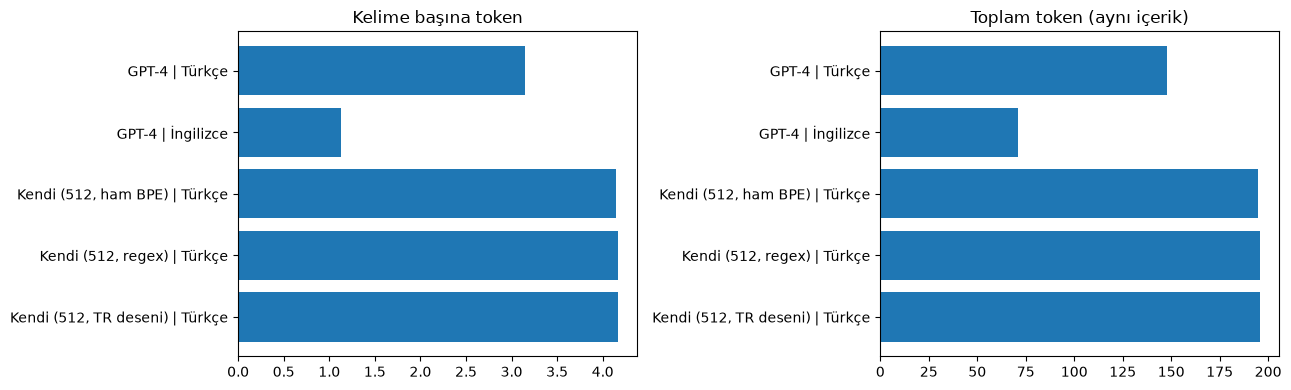

In [17]:
# Görselleştirme: kelime başına token ve toplam token
adlar = [a for a, _, _ in satirlar]
kelimeler = [k for _, k, _ in satirlar]
tokenlar = [t for _, _, t in satirlar]

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].barh(adlar, [t / k for k, t in zip(kelimeler, tokenlar)])
ax[0].set_title("Kelime başına token")
ax[1].barh(adlar, tokenlar)
ax[1].set_title("Toplam token (aynı içerik)")
for a in ax:
    a.invert_yaxis()
plt.tight_layout()
plt.show()

### Eklemeli yapı sayıları nasıl etkiliyor?
Türkçe eklemeli bir dil: tek kelimeye birden fazla ek gelir (`kütüphanelerde` = kütüphane + ler + de), bu yüzden bir Türkçe kelime çoğu zaman 2-3 İngilizce kelimeye denk gelir. Kelime sayısı Türkçede daha düşük, ama yüzey biçimlerin sayısı çok yüksek: aynı kök yüzlerce farklı biçimde yazılabilir. İngilizce ağırlıklı veriyle eğitilen `cl100k_base` bu uzun ve nadir biçimleri tek token yapacak kadar sık görmemiştir, bu yüzden kelimeleri küçük parçalara böler ve **kelime başına token** artar. Toplam token karşılaştırması, kelime başına oranın bu farkı tek başına olduğundan büyük ya da küçük gösterip göstermediğini kontrol etmenin daha adil yoludur.

Kendi tokenizer'ımız yalnızca 512 vocab'a sahip olduğu için GPT-4'ün yaklaşık 100.000'lik vocab'ından çok daha az sıkıştırır. Bu satırlar GPT-4'le sayısal olarak yarıştırılmak için değil, "Türkçe metinde eğitmek hangi birleşmeleri öne çıkarıyor" sorusunu göstermek içindir. Ayrıca Nutuk eski bir dönem Türkçesi içerdiği için bugünün konuşma diline ait kelimelerde (örnek paragraf gibi) sonuç beklenenden kötü çıkabilir.

## 6. Görselleştirmeler

### 6.1 BPE küçük bir örnekte adım adım

In [18]:
def bpe_adim_adim(metin, n_merge=6):
    ids = list(metin.encode("utf-8"))
    vocab = {i: bytes([i]) for i in range(256)}
    print("Başlangıç:", [tok_str(vocab[t]) for t in ids])
    for i in range(n_merge):
        stats = get_stats(ids)
        if not stats:
            break
        pair = max(stats, key=stats.get)
        idx = 256 + i
        ids = merge(ids, pair, idx)
        vocab[idx] = vocab[pair[0]] + vocab[pair[1]]
        print(f"\nAdım {i+1}: {tok_str(vocab[pair[0]])} + {tok_str(vocab[pair[1]])} -> {tok_str(vocab[idx])}  (x{stats[pair]})")
        print("  ", [tok_str(vocab[t]) for t in ids], f"({len(ids)} token)")

bpe_adim_adim("kitaplarında kitapları kitaplar")

Başlangıç: ["'k'", "'i'", "'t'", "'a'", "'p'", "'l'", "'a'", "'r'", "b'\\xc4'", "b'\\xb1'", "'n'", "'d'", "'a'", "' '", "'k'", "'i'", "'t'", "'a'", "'p'", "'l'", "'a'", "'r'", "b'\\xc4'", "b'\\xb1'", "' '", "'k'", "'i'", "'t'", "'a'", "'p'", "'l'", "'a'", "'r'"]

Adım 1: 'k' + 'i' -> 'ki'  (x3)
   ["'ki'", "'t'", "'a'", "'p'", "'l'", "'a'", "'r'", "b'\\xc4'", "b'\\xb1'", "'n'", "'d'", "'a'", "' '", "'ki'", "'t'", "'a'", "'p'", "'l'", "'a'", "'r'", "b'\\xc4'", "b'\\xb1'", "' '", "'ki'", "'t'", "'a'", "'p'", "'l'", "'a'", "'r'"] (30 token)

Adım 2: 'ki' + 't' -> 'kit'  (x3)
   ["'kit'", "'a'", "'p'", "'l'", "'a'", "'r'", "b'\\xc4'", "b'\\xb1'", "'n'", "'d'", "'a'", "' '", "'kit'", "'a'", "'p'", "'l'", "'a'", "'r'", "b'\\xc4'", "b'\\xb1'", "' '", "'kit'", "'a'", "'p'", "'l'", "'a'", "'r'"] (27 token)

Adım 3: 'kit' + 'a' -> 'kita'  (x3)
   ["'kita'", "'p'", "'l'", "'a'", "'r'", "b'\\xc4'", "b'\\xb1'", "'n'", "'d'", "'a'", "' '", "'kita'", "'p'", "'l'", "'a'", "'r'", "b'\\xc4'", "b'\\xb1'"

### 6.2 Regex'in metni nasıl böldüğü

In [19]:
import html
from IPython.display import HTML, display

def goster_parcalar(s, pattern):
    """Her parçayı farklı renkte gösterir. Boşluk '·' ile işaretlenir."""
    renkler = ["#cfe8ff", "#ffe0b3", "#d5f5d0", "#f5d0e6", "#e6e0ff"]
    out = []
    for i, ch in enumerate(re.findall(pattern, s)):
        g = html.escape(ch).replace(" ", "·").replace("\n", "\\n")
        out.append(f'<span style="background:{renkler[i % len(renkler)]};color:#000;padding:2px 4px;margin:1px;border-radius:3px;font-family:monospace">{g}</span>')
    return "".join(out)

for s in ["Ankara'dan İstanbul'da", "Ankara’dan İstanbul’da"]:
    display(HTML(f"<p><b>GPT-4 deseni:</b> {goster_parcalar(s, gpt4_pattern)}</p>"))
    display(HTML(f"<p><b>TR deseni:</b> &nbsp;&nbsp;{goster_parcalar(s, tr_pattern)}</p>"))

### 6.3 Vocab boyutu ve sıkıştırma oranı

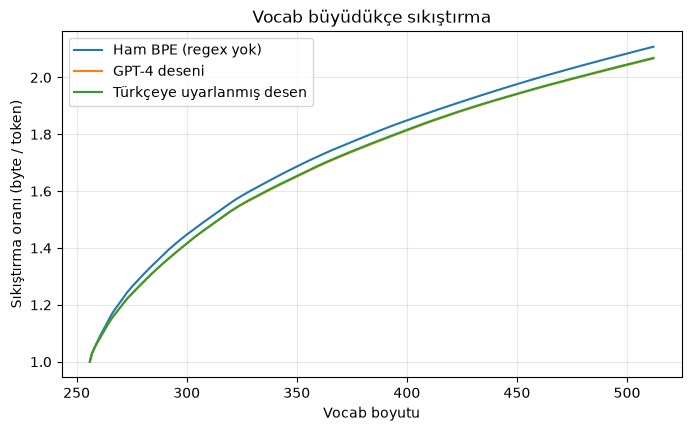

In [20]:
plt.figure(figsize=(8, 4.5))
plt.plot(*zip(*hist_plain), label="Ham BPE (regex yok)")
plt.plot(*zip(*hist_rx),    label="GPT-4 deseni")
plt.plot(*zip(*hist_tr),    label="Türkçeye uyarlanmış desen")
plt.xlabel("Vocab boyutu")
plt.ylabel("Sıkıştırma oranı (byte / token)")
plt.title("Vocab büyüdükçe sıkıştırma")
plt.grid(alpha=0.3)
plt.legend()
plt.show()